In [1]:
import pandas as pd
file_path = "data/online retail.xlsx"
df = pd.read_excel(file_path)

print(df.shape)
print(df.head())
print(df.info())
print(df.isna().sum())

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       ----------

In [2]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"],errors="coerce")


#remove canceled invoices ,invalid records,and rows miising key fields
df = df.dropna(subset=["InvoiceDate","InvoiceNo","StockCode"])
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[df["Quantity"]>0 & (df["UnitPrice"]>0)]

#calculate revenue for each product line
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Rows after cleaning:", len(df))
print(df[["InvoiceDate","InvoiceNo","StockCode","Quantity","UnitPrice","Revenue"]].head())

Rows after cleaning: 531285
          InvoiceDate InvoiceNo StockCode  Quantity  UnitPrice  Revenue
0 2010-12-01 08:26:00    536365    85123A         6       2.55    15.30
1 2010-12-01 08:26:00    536365     71053         6       3.39    20.34
2 2010-12-01 08:26:00    536365    84406B         8       2.75    22.00
3 2010-12-01 08:26:00    536365    84029G         6       3.39    20.34
4 2010-12-01 08:26:00    536365    84029E         6       3.39    20.34


In [23]:
top_10_products = df.groupby("StockCode")["Revenue"].sum().sort_values(ascending=False).head(10)
print("Top 10 products by revenue:")
print(top_10_products)

Top 10 products by revenue:
StockCode
DOT       206248.77
22423     174484.74
23843     168469.60
85123A    104518.80
47566      99504.33
85099B     94340.05
23166      81700.92
M          78110.27
POST       78101.88
23084      66964.99
Name: Revenue, dtype: float64


In [3]:
import sqlite3
db_path = "data/Online Retails.db"

with sqlite3.connect(db_path) as conn:
    df.to_sql("sales", conn, if_exists="replace", index=False)
print("saved cleaned data to", db_path)

saved cleaned data to data/Online Retails.db


In [4]:
monthly_sql ="""
SELECT
    strftime('%Y-%m', InvoiceDate) AS month,
    ROUND(SUM(Revenue),2) AS Revenue
FROM sales
GROUP BY month
ORDER BY month;
"""

with sqlite3.connect(db_path) as conn:
    monthly_sales = pd.read_sql_query(monthly_sql, conn)
monthly_sales.sort_values("Revenue", ascending=False, inplace=True)
print(monthly_sales)
 

      month     Revenue
11  2011-11  1509496.33
10  2011-10  1154979.30
9   2011-09  1058590.17
0   2010-12   823746.14
5   2011-05   770536.02
6   2011-06   761739.90
8   2011-08   737014.26
7   2011-07   719221.19
3   2011-03   717639.36
1   2011-01   691364.56
12  2011-12   638792.68
4   2011-04   537808.62
2   2011-02   523631.89


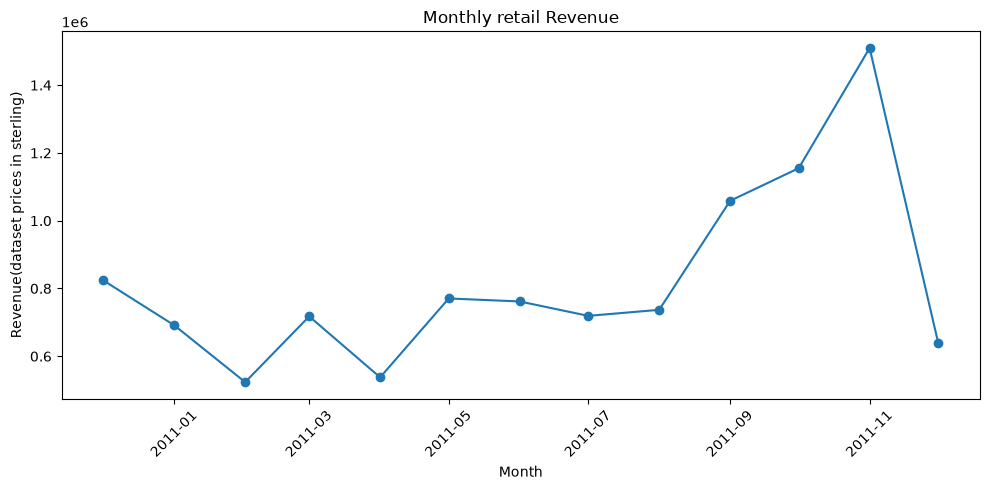

In [8]:
import matplotlib.pyplot as plt

monthly_sales["month"] = pd.to_datetime(monthly_sales["month"])
monthly_sales = monthly_sales.sort_values("month")

plt.figure(figsize=(10,5))
plt.plot(monthly_sales["month"], monthly_sales["Revenue"], marker="o")
plt.title("Monthly retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue(dataset prices in sterling)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import mean_absolute_error
series = monthly_sales.set_index("month")["Revenue"].asfreq("MS")

series = series.fillna(0)
test_size = 3

if len(series) <= test_size:
    raise ValueError("Not enough monthly observations for this test.")

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

history = list(train)
predictions = []
for actual_value in test:
    predictions.append(history[-1])
    history.append(actual_value)

mae = mean_absolute_error(test, predictions)
print("Mean absolute error:",round(mae,2))

forecast_results = pd.DataFrame({"actual": test, "predicted": predictions}, index=test.index)

forecast_results


Mean absolute error: 440536.6


,actual,predicted
month,,
2011-10-01,1154979.30,1058590.17
2011-11-01,1509496.33,1154979.30
2011-12-01,638792.68,1509496.33


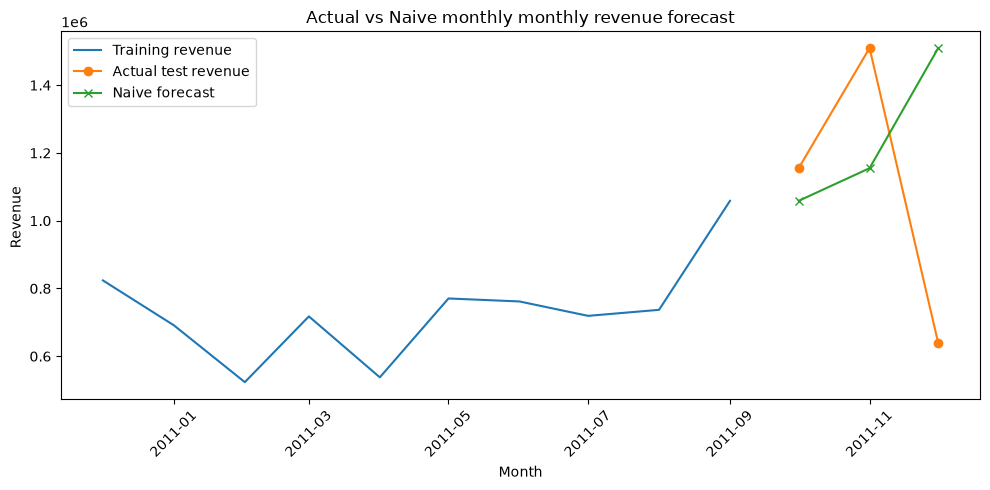

In [17]:
plt.figure(figsize = (10,5))
plt.plot(train.index,train.values,label = "Training revenue")
plt.plot(test.index,test.values,marker = "o",label = "Actual test revenue")
plt.plot(test.index,predictions,marker = "x",label = "Naive forecast ")
plt.title("Actual vs Naive monthly monthly revenue forecast")
plt.xlabel("Month")
plt.ylabel("Revenue ")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
plt.savefig("figures/forecast_comparison.png",dpi=150,bbox_inches="tight")

<Figure size 640x480 with 0 Axes>